In [ ]:
%reload_ext autoreload
%autoreload 2

import warnings, os, sys
warnings.filterwarnings('ignore')
from IPython.display import clear_output

import numpy as np
import pandas as pd
import swifter
import ast
from functools import reduce
from tqdm.auto import tqdm

from rdkit import Chem
from rdkit.Chem import PandasTools
from rdkit import RDLogger; RDLogger.DisableLog('rdApp.*')

from rdkit.Chem.Draw import IPythonConsole
IPythonConsole.ipython_useSVG = True
IPythonConsole.molSize = 600, 400
IPythonConsole.drawOptions.addAtomIndices = False

import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
pio.renderers.default = "notebook"
pio.renderers.default_config = {
    "toImageButtonOptions": {"format": "png", "scale": 5}}

# sys.path.append(os.path.abspath(R"C:\\Users\\Idener\\Sync\\CODE"))
# from aiddtools import fingerprint_tools as fpt
clear_output()

In [ ]:
palette_1 = ["#0D4A70", "#3082BD", "#9EC9E2", "#E4F1F7"]
geodataviz_diverging_1 = ["#045275", "#089099", "#39B185", "#7CCBA2", "#FCDE9C",
                          "#EEB479", "#E88471", "#7C1D6F", "#CF597E", "#9A275A"]
node_colors = ['#d10808', '#ffc32d','#009b73']

## Fragment analysis

In [5]:
df_fragments = pd.read_csv('NPA_fragments.csv', header=None,
    names=['NPA_ID', 'ISOSMILES', 'Frag_ISOSMILES', 'Frag_IDs'])
df_fragments['Frag_ISOSMILES'] = (df_fragments['Frag_ISOSMILES'].str.strip('[]').str.split(','))
df_fragments['Frag_IDs'] = (df_fragments['Frag_IDs'].str.strip('[]').str.split(','))

df_fragmented = df_fragments[df_fragments['Frag_IDs'].apply(lambda x: len(x) > 1)]
df_whole = df_fragments[df_fragments['Frag_IDs'].apply(lambda x: len(x) == 1)]

In [49]:
df_expl = df_fragmented.explode(['Frag_IDs', 'Frag_ISOSMILES'])
df_expl = df_expl.drop_duplicates(subset=['Frag_IDs'])

# Before similarity search
green_i = df_expl['Frag_IDs'].str.startswith(('C', 'L')).sum()
red_i = (~df_expl['Frag_IDs'].str.startswith(('C', 'L'))).sum()

# After similarity search
green_f = green_i
yellow_f = df_expl['Frag_IDs'].str.startswith(('~', '<')).sum()
red_f = (df_expl['Frag_IDs'] == '').sum()

In [70]:
# Prepare data
labels_before = ['No annotation', 'Direct annotation']
values_before = [red_i, green_i]
perc_before = [v / sum(values_before) * 100 for v in values_before]

labels_after = ['No annotation', 'Similarity-based<br>annotation', 'Direct annotation']
values_after = [red_f, yellow_f, green_f]
perc_after = [v / sum(values_after) * 100 for v in values_after]

# Create subplots
fig = make_subplots(rows=1, cols=2,
    subplot_titles=['Before MSC', 'After MSC'])
for ann in fig.layout.annotations:
    if ann.text in ['Before MSC', 'After MSC']:
        ann.y += 0.04

fig.add_trace(go.Bar(
    x=labels_before,
    y=perc_before,
    text=[f"{p:.1f}%" for p in perc_before],
    textposition='outside',
    marker_color=[palette_1[2], palette_1[0]]),
    row=1, col=1)

fig.add_trace(go.Bar(
        x=labels_after,
        y=perc_after,
        text=[f"{p:.1f}%" for p in perc_after],
        textposition='outside',
        marker_color=[palette_1[2], palette_1[1], palette_1[0]]),
    row=1, col=2)

fig.update_layout(
    width=950, height=420,
    margin=dict(t=60, b=50, l=70, r=40),

    font=dict(family="sans-serif"),
    showlegend=False,
    plot_bgcolor='white',
    paper_bgcolor='white')

# Axis labels
fig.update_yaxes(title_text='Percentage of total fragments (%)', row=1, col=1)
fig.update_yaxes(title_text='', row=1, col=2)
fig.update_yaxes(showgrid=True, gridcolor='lightgrey', range=[0, 101], mirror=True
                 , title_font=dict(size=17))
fig.update_xaxes(showline=True, linewidth=3, linecolor='black',
    mirror=False, title_font=dict(size=17), tickfont=dict(size=16))

fig.data[0].width = [0.4] * len(x_labels)  # subplot 1
fig.data[1].width = [0.6] * len(x_labels)  # subplot 2
fig.show(config={"toImageButtonOptions": {"format": "png", "scale": 5}})


In [ ]:
import pandas as pd
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# --- BEFORE similarity search (only 'C' counts as annotated)
annot_before = df_fragmented['Frag_IDs'].apply(
    lambda x: sum(i.startswith(('C', 'L')) for i in x) / len(x) * 100)

# --- AFTER similarity search ('C', '~', '<' count as annotated)
annot_after = df_fragmented['Frag_IDs'].apply(
    lambda x: sum(i.startswith(('C', 'L', '~', '<')) for i in x) / len(x) * 100)

# Define bins and labels
bins = [0, 0.1, 25, 50, 75, 99.9, 100]
labels = ['0%', '0.1–25%', '25–50%', '50–75%', '75–99.9%', '100%']

# Bin the annotation percentages
before_bins = pd.cut(annot_before, bins=bins, labels=labels, include_lowest=True)
after_bins = pd.cut(annot_after, bins=bins, labels=labels, include_lowest=True)

# Compute percentage distribution of compounds per bin
before_dist = before_bins.value_counts(normalize=True).sort_index() * 100
after_dist = after_bins.value_counts(normalize=True).sort_index() * 100


x_labels = labels
y_before = before_dist.reindex(x_labels).fillna(0)
y_after = after_dist.reindex(x_labels).fillna(0)

color_map = {
    '0%':       palette_1[2],
    '0.1–25%':  palette_1[1],
    '25–50%':   palette_1[1],
    '50–75%':   palette_1[1],
    '75–99.9%': palette_1[1],
    '100%':     palette_1[0]}

fig = make_subplots(rows=1, cols=2,
    subplot_titles=['Before MSC', 'After MSC'])
for ann in fig.layout.annotations:
    ann.y += 0.04

fig.add_trace(go.Bar(
    x=x_labels, y=y_before,
    marker_color=[color_map[x] for x in x_labels],
    text=[f'{v:.1f}%' for v in y_before],
    textposition='outside'),
    row=1, col=1)

fig.add_trace(go.Bar(
    x=x_labels, y=y_after,
    marker_color=[color_map[x] for x in x_labels],
    text=[f'{v:.1f}%' for v in y_after],
    textposition='outside'),
    row=1, col=2)

fig.update_layout(
    width=950, height=420,
    margin=dict(t=60, b=70, l=70, r=40),

    font=dict(family="sans-serif"),
    showlegend=False,
    plot_bgcolor='white',
    paper_bgcolor='white')

# Axis labels
fig.update_yaxes(title_text='Percentage of total compounds (%)', row=1, col=1)
fig.update_yaxes(title_text='', row=1, col=2)
fig.update_yaxes(showgrid=True, gridcolor='lightgrey', range=[0, 41],
    mirror=True, title_font=dict(size=17))
fig.update_xaxes(showline=True, linewidth=3, linecolor='black',
    mirror=False)

fig.add_annotation(
    text="Percentage of annotated fragments per compound",
    xref="paper", yref="paper",
    x=0.5, y=-0.18,
    showarrow=False,
    font=dict(size=17))

fig.show(config={"toImageButtonOptions": {"format": "png", "scale": 5}})

In [77]:
n_atom_list = []
for row in df_fragmented.itertuples():
    aux = []
    for smi in row.Frag_ISOSMILES:
        try:
            aux.append(Chem.MolFromSmiles(smi).GetNumAtoms())
        except:
            aux.append(0)
    n_atom_list.append(aux)
df_fragmented['Frag_N_atoms'] = n_atom_list

percent_annot_atoms_i = []
for row in df_fragmented.itertuples():
    indices = [i for i, id in enumerate(row.Frag_IDs) if id.startswith(('C', 'L'))]
    n_atom_red_nodes = sum(row.Frag_N_atoms[i] for i in indices)
    n_atom_compound = sum(row.Frag_N_atoms)
    percent_annot_atoms_i.append(round(n_atom_red_nodes/n_atom_compound*100, 2))
df_fragmented['percent_annot_atoms_i'] = percent_annot_atoms_i

percent_annot_atoms_f = []
for row in df_fragmented.itertuples():
    indices = [i for i, id in enumerate(row.Frag_IDs) if id != '']
    n_atom_red_nodes = sum(row.Frag_N_atoms[i] for i in indices)
    n_atom_compound = sum(row.Frag_N_atoms)
    percent_annot_atoms_f.append(round(n_atom_red_nodes/n_atom_compound*100, 2))
df_fragmented['percent_annot_atoms_f'] = percent_annot_atoms_f

In [ ]:
# Create subplots
fig = make_subplots(rows=1, cols=2,
    subplot_titles=['Before MSC', 'After MSC'])
for ann in fig.layout.annotations:
    ann.y += 0.04

bins = [0, 0.1, 25, 50, 75, 99.9, 100]
labels = ['0%', '0.1–25%', '25–50%', '50–75%', '75–99.9%', '100%']

for i, col in enumerate(['percent_annot_atoms_i', 'percent_annot_atoms_f']):
    # Bin the values
    binned = pd.cut(df_fragmented[col], bins=bins, labels=labels,
                    include_lowest=True)

    # Compute normalized percentage per bin
    counts = binned.value_counts().sort_index()
    perc = counts / counts.sum() * 100

    # Add bar
    fig.add_trace(go.Bar(
        x=labels,
        y=perc,
        text=[f"{p:.1f}%" for p in perc],
        textposition='outside',
        marker_color=[palette_1[2]] + [palette_1[1]]*(len(labels)-2) + [palette_1[0]]),
        row=1, col=i+1)

fig.update_layout(
    width=950, height=420,
    margin=dict(t=60, b=70, l=70, r=40),

    font=dict(family="sans-serif"),
    showlegend=False,
    plot_bgcolor='white',
    paper_bgcolor='white')

# Axis labels
fig.update_yaxes(title_text='Percentage of total compounds (%)', row=1, col=1)
fig.update_yaxes(title_text='', row=1, col=2)
fig.update_yaxes(showgrid=True, gridcolor='lightgrey', range=[0, 41],
    mirror=True, title_font=dict(size=17))
fig.update_xaxes(showline=True, linewidth=3, linecolor='black',
    mirror=False)

fig.add_annotation(
    text="Percentage of annotated atoms per compound",
    xref="paper", yref="paper",
    x=0.5, y=-0.18,
    showarrow=False,
    font=dict(size=17))

fig.show(config={"toImageButtonOptions": {"format":"png", "scale":5}})


In [115]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import pandas as pd

# Explode and remove red nodes (U)
all_ids = df_fragmented['Frag_IDs'].explode()
all_ids = all_ids[all_ids != '']

# Count frequency
freq = all_ids.value_counts().reset_index()
freq.columns = ['ID', 'Count']
freq['Percent'] = freq['Count'] / freq['Count'].sum() * 100

# Top 15 green and yellow by percent
top_green = freq[freq['ID'].str.startswith(('C', 'L'))].head(15)
top_yellow = freq[freq['ID'].str.startswith(('~'))].head(15)

# Create subplots
fig = make_subplots(rows=1, cols=2,
    subplot_titles=['Direct annotation', 'Similarity-based annotation'])
for ann in fig.layout.annotations:
    ann.y += 0.04

# Green bars
fig.add_trace(go.Bar(
    x=top_green['ID'],
    y=top_green['Percent'],
    marker_color=palette_1[0]),
    row=1, col=1)

# Yellow bars
fig.add_trace(
    go.Bar(
        x=[x.strip('~') for x in top_yellow['ID']],
        y=top_yellow['Percent'],
        marker_color=palette_1[1]),
    row=1, col=2)

fig.update_layout(
    width=950, height=420,
    margin=dict(t=60, b=70, l=70, r=40),

    font=dict(family="sans-serif"),
    showlegend=False,
    plot_bgcolor='white',
    paper_bgcolor='white')

# Axis labels
fig.update_yaxes(title_text='Percent occurrence (%)', range=[0, 6.1], row=1, col=1)
fig.update_yaxes(title_text='', range=[0, 1.21], row=1, col=2)
fig.update_yaxes(showgrid=True, gridcolor='lightgrey',
    mirror=True, title_font=dict(size=17))
fig.update_xaxes(showline=True, linewidth=3, linecolor='black',
    mirror=False, tickangle=-45)


fig.show(config={"toImageButtonOptions": {"format":"png", "scale":5}})

In [ ]:
# Get top 25 green and yellow nodes
top_green = freq[freq['Category'] == 'Green (C)'].head(24)
top_yellow = freq[freq['Category'] == 'Yellow (~)'].head(24)

# Get corresponding mol from df_BUL
top_green['ROMol'] = top_green['ID'].apply(lambda x: df_BUL[df_BUL['ID'] == x]['ROMol'].values[0])
top_yellow['ROMol'] = top_yellow['ID'].apply(lambda x: df_BUL[df_BUL['ID'] == x.replace('~', '')]['ROMol'].values[0])

import mols2grid
mols2grid.display(top_green,
    mol_col='ROMol',
    n_items_per_page=25,
    sub_img_size=(200, 200),
    style={"ID": lambda x: "font-weight: bold;"},
    subset=["ID", "Count"],
    use_svg=True,
    show_index=False)

In [ ]:
mols2grid.display(top_yellow,
    mol_col='ROMol',
    n_items_per_page=25,
    sub_img_size=(200, 200),
    style={"ID": lambda x: "font-weight: bold;"},
    subset=["ID", "Count"],
    use_svg=True,
    show_index=False)

## Work on UUs

In [ ]:
# df_metacyc = pd.read_csv(R"C:\Users\Idener\Desktop\biosynthetic_chains_smiles.tsv", sep='\t', header=None)

# Extract adjacent pairs of SMILES
# pairs = []
# for _, row in df_metacyc.iterrows():
#     smiles_chain = [s for s in row if pd.notna(s) and str(s).strip() != ""]
#     for i in range(len(smiles_chain) - 1):
#         pairs.append((smiles_chain[i], smiles_chain[i+1]))
# df_pairs = pd.DataFrame(pairs, columns=["Reactant", "Product"])
# PandasTools.AddMoleculeColumnToFrame(df_pairs, smilesCol='Reactant', molCol='ROMol_R')
# PandasTools.AddMoleculeColumnToFrame(df_pairs, smilesCol='Product', molCol='ROMol_P')

# df_pairs['MACCS_R'] = df_pairs['ROMol_R'].swifter.apply(lambda x: fpt.calculate_fp(x, method='maccs'))
# df_pairs['MACCS_P'] = df_pairs['ROMol_P'].swifter.apply(lambda x: fpt.calculate_fp(x, method='maccs'))
# df_pairs['Similarity_MACCS'] = df_pairs.swifter.apply(lambda row: fpt.get_similarity(row['MACCS_R'], row['MACCS_P'], 'maccs'), axis=1)

df_pairs['MAP4_R'] = df_pairs['ROMol_R'].swifter.apply(lambda x: fpt.calculate_fp(x, method='map4'))
df_pairs['MAP4_P'] = df_pairs['ROMol_P'].swifter.apply(lambda x: fpt.calculate_fp(x, method='map4'))
df_pairs['Similarity_MAP4'] = df_pairs.swifter.apply(lambda row: fpt.get_similarity(row['MAP4_R'], row['MAP4_P'], 'map4'), axis=1)

df_pairs

In [ ]:
# Calculate similarity matrix between df_UUL and df_BUL
# df_UUL = pd.read_pickle('../data/Database_UUL.pkl')
# df_BUL = pd.read_pickle('../data/Database_NEWBUL.pkl')

method = 'MACCS'

fps_1 = df_UUL['ROMol'].swifter.apply(lambda x: fpt.calculate_fp(x, method=method))
fps_2 = df_BUL['ROMol'].swifter.apply(lambda x: fpt.calculate_fp(x, method=method))
sim_matrix = fpt.get_similarity_matrix(fps_1, fps_2, method=method)
# np.savez_compressed(f"UUL_similarity_matrix_{method}.npz", sim_matrix=sim_matrix)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Flatten similarity matrix (ignore diagonal if fps_1 is fps_2)
all_scores = sim_matrix.flatten()
if fps_1 is fps_2:  # self-similarity case
    all_scores = all_scores[~np.eye(sim_matrix.shape[0], dtype=bool)]

# Plot histogram
plt.hist(all_scores, bins=50, edgecolor='black', alpha=0.7)
plt.xlabel("Similarity")
plt.ylabel("Frequency")
plt.title(f"Distribution of pairwise similarities ({method})")
plt.show()

# Optional: print some quantiles to see typical ranges
quantiles = np.quantile(all_scores, [0.05, 0.25, 0.5, 0.75, 0.95])
print("Quantiles (5%,25%,50%,75%,95%):", quantiles)


In [ ]:
"""
Match UUL molecules to the most similar BU.

For each molecule in the UUL dataset:
- Sort the BUL similarities in descending order.
- Identify the most similar BUL molecule with a Tanimoto similarity ≥ 0.6.
- Accept the match only if the number of heavy atoms differs by no more than 3.
- Record UID, ISOSMILES from UUL and ID, ISOSMILES from BUL along with the similarity score.
"""

data = []
for u_idx, row in enumerate(sim_matrix):
    uid_atoms = df_UUL.iloc[u_idx]['ROMol'].GetNumHeavyAtoms()
    sorted_indices = np.argsort(row)[::-1]
    sorted_values = row[sorted_indices]

    aux_list = [df_UUL.iloc[u_idx]['UID'], df_UUL.iloc[u_idx]['ISOSMILES']]
    for k_idx, sim_value in zip(sorted_indices, sorted_values):
        if sim_value >= 0.8:
            kid_atoms = df_BUL.iloc[k_idx]['ROMol'].GetNumHeavyAtoms()
            if abs(uid_atoms - kid_atoms) <= 3:
                aux_list.extend([df_BUL.iloc[k_idx]['ID'],
                                df_BUL.iloc[k_idx]['ISOSMILES'],
                                float(sim_value)])
                break
    if len(aux_list) == 2:
        aux_list.extend([None, None, None])
    data.append(aux_list)

df_UUL_sim = pd.DataFrame(data, columns=['UID', 'ISOSMILES', 'Similar_KID', 'Similar_ISOSMILES', 'Similarity'])
df_UUL_sim.to_csv(f'../data/Database_UUL_{method}.csv', index=False)

In [ ]:
df_UUL = pd.read_csv(f'../data/Database_UUL_{method}.csv')
df_fragmented = pd.read_pickle('geass_NPA_fragmented.pkl')

fragmented_sim, sim_values = [], []
for lst in tqdm(df_fragmented['Frag_IDs'].tolist()):
    lst_aux1, lst_aux2 = [], []
    for id in lst:
        if 'U' in id:
            df_aux = df_UUL[df_UUL['UID'] == id]
            if df_aux.shape[0] > 0:
                if df_aux['Similarity'].values[0] == 1:  #<-- Some units are not recognised by geass due to tautomerism/chirality
                    kid = df_aux['Similar_KID'].values[0]
                    lst_aux1.append(kid)
                    lst_aux2.append(1.0)

                elif df_aux['Similarity'].values[0] >= 0.6:
                    kid = df_aux['Similar_KID'].values[0]
                    lst_aux1.append(f"~{kid}")
                    lst_aux2.append(df_aux['Similarity'].values[0])
                else:
                    lst_aux1.append(id)
                    lst_aux2.append(0.0)
            else:
                lst_aux1.append(id)
                lst_aux2.append(0.0)
        else:
            lst_aux1.append(id)
            lst_aux2.append(0.0)
                
    fragmented_sim.append(lst_aux1)
    sim_values.append([float(x) for x in lst_aux2])

df_fragmented['Frag_sim_IDs'] = fragmented_sim
df_fragmented['Frag_sim_values'] = sim_values

df_fragmented.to_pickle('geass_NPA_fragmented.pkl')

## Analysis of the unknown unit library

In [ ]:
df_UUL_sim = pd.read_csv(f'../data/Database_UUL_{method}.csv')

# Define bin edges and labels
bins = np.linspace(0, 1, 11)  # 0.0, 0.1, ..., 1.0
bins = np.append(bins, 1.0001)  # Extend upper bound slightly to include 1.0 with right=False
bin_labels = [f"{bins[i]:.2f}-{bins[i+1] - 0.01:.2f}" for i in range(len(bins) - 2)] + ["1 (exact)"]

# Bin the similarity values with left-inclusive, right-exclusive intervals
df_UUL_sim['Similarity_Bin'] = pd.cut(df_UUL_sim['Similarity'], bins=bins, labels=bin_labels,
                                  include_lowest=True, right=False)

# Count values per bin and prepare DataFrame for plotting
counts = df_UUL_sim['Similarity_Bin'].value_counts().sort_index()
hist_df = pd.DataFrame({
    'Bin': bin_labels,
    'Count': counts.values,
    'Text': [str(c) for c in counts.values]})
hist_df['Color'] = ['#d10808'] * 6 + ['#ffc32d'] * 4 + ['#009b73']

In [ ]:
# Plot histogram using Plotly
fig = px.bar(
    hist_df,
    x='Bin',
    y='Count',
    text='Text',
    color='Color',
    color_discrete_map='identity',  # use exact color names
    labels={'Bin': f'Similarity Range ({method})', 'Count': 'Frequency'})

fig.update_layout(
    xaxis_title= f'Similarity Range ({method})',
    yaxis_title='Count',
    font=dict(family="sans-serif"),
    bargap=0.1,
    width=800,
    height=400)

fig.show(config={"toImageButtonOptions": {"format":"svg", "scale":5}})

print(f"""======= UUL Summary =======
      
UUs with direct annotation: {len(df_UUL[df_UUL['Similarity'] == 1])}
UUs with similarity annotation (sim >= 0.6): {len(df_UUL[(df_UUL['Similarity'] < 1) & (df_UUL['Similarity'] >= 0.6)])}
UUs with no annotation (sim < 0.6): {len(df_UUL[df_UUL['Similarity'] < 0.6])}
Total UUs: {len(df_UUL)}
""")

## Analysis of unfragmented compounds

In [ ]:
df_unfragmented = pd.read_pickle('geass_NPA_unfragmented.pkl')
# PandasTools.AddMoleculeColumnToFrame(df_unfragmented, smilesCol='SMILES')
df_unfragmented['FP'] = df_unfragmented['ROMol'].apply(lambda mol: calculate_fp(mol, method='torsion'))
df_unfragmented['MW'] = df_unfragmented['ROMol'].apply(lambda x: Descriptors.MolWt(x))

for i, row in tqdm(df_unfragmented.iterrows(), total=df_unfragmented.shape[0]):
    # Reduce the number of compounds by filtering BUs by MW
    f_aux = df_BUL[(df_BUL['MW'] - 70 <= row['MW']) & (df_BUL['MW'] + 70 >= row['MW'])]

    if len(df_aux) > 0:
        df_aux['similarity'] = df_aux['FP'].apply(lambda x: TanimotoSimilarity(x, row.FP))

        max = df_aux.loc[df_aux['similarity'].idxmax()]
        if max['similarity'] == 1:
            df_unfragmented.loc[i, 'Exact_KID'] = max.ID
        elif max['similarity'] >= 0.6:
            df_unfragmented.loc[i, 'Similar_KID'] = max.ID
            df_unfragmented.loc[i, 'Similar_ISOSMILES'] = max.ISOSMILES
df_unfragmented

In [7]:
df_unfragmented = pd.read_pickle('geass_NPA_unfragmented.pkl')
df_unfragmented = df_unfragmented.explode('Fragments')

import mols2grid
mols2grid.display(df_unfragmented.head(200), smi_col='Fragments')

MolGridWidget()

In [ ]:
from molcomplib import MolCompass
compass = MolCompass()

df_unfragmented = pd.read_pickle('geass_NPA_unfragmented.pkl')

res = compass.process(df_unfragmented)

In [ ]:
from bokeh_graph import bokeh_plot

df_match = df_unfragmented[(df_unfragmented['Exact_KID'].notna()) | (df_unfragmented['Similar_KID'].notna())]
df_match['Matched_ID'] = df_match['Exact_KID'].fillna(df_match['Similar_KID'])
df_match = df_match.merge(df_BUL[['ID', 'BRITE']], left_on='Matched_ID', right_on='ID', how='left')
df_match = df_match.dropna(subset=['BRITE'])
df_match['BRITE_code'] = df_match['BRITE'].apply(lambda x: x.split('[')[1].split(']')[0].strip())
df_match['BRITE_code'] = df_match.apply(
    lambda row: row['BRITE'].split('\n')[2].strip() if row['BRITE_code'] in ['BR:br08002'] else row['BRITE_code'],
    axis=1
)
df_match['BRITE_code_int'] = df_match['BRITE_code'].astype('category').cat.codes

bokeh_plot(df_match, "BRITE_code_int", id_field="npaid",
           smiles_column='compound_smiles',
           additional_labels=["origin_type", "BRITE_code"])

In [ ]:
print(f'''
    NP Atlas > {len(df_NPA)} total compounds
               {len(fragmented)} compounds fragmented
                  {len(complete)} compounds with direct annotations (all green nodes)
                  {sum(1 for lst in fragmented_sim if any('~' in x for x in lst))} compounds with similarity annotation (g+y+r nodes)
               {len(whole)} compounds not fragmented
                  {len(df_unfragmented['Exact_KID'].dropna())} compounds with direct annotation (one green node)
                  {len(df_unfragmented['Similar_KID'].dropna())} compounds with similarity annotation (one yellow node)
                  {len(whole)-len(df_unfragmented['Exact_KID'].dropna())-len(df_unfragmented['Similar_KID'].dropna())} compounds with no annotation (one red node)

    Building units > {len(df_BUL)} total BUs in BUL
                     {len(set(x for lst in fragmented_sim for x in lst if 'C' in x))} unique BUs recognized
                     {len(set(x for lst in fragmented_sim for x in lst if '~' in x))} similar BUs recognized
                     {len(set(x for lst in fragmented_sim for x in lst if x.startswith('U')))} BUs not recognized
      ''')

In [ ]:
# replace '' with 0.5
df_UUL['Similarity'] = df_UUL['Similarity'].replace('NA', 0.0)
df_UUL['Similarity'] = df_UUL['Similarity'].astype(float)


## Case Study: Beauverichelin A and Forazoline A

In [ ]:
database3 = pd.read_csv('../data/Database3.csv')
database3 = database3[~database3['ID'].str.contains('SS')]
PandasTools.AddMoleculeColumnToFrame(database3, smilesCol='ISOSMILES')

In [ ]:
# # Find compounds with the highest number of different bonds
# data = []
# for row in database3.itertuples():
#     try:
#         geass = Geass()
#         f = geass.get_fragments(row.ROMol)
#         b = set(list(geass.get_bonds_to_break().values()))
#         data.append([row.ID, f, b])
#     except: pass

# df_data = pd.DataFrame(data, columns=['ID', 'Fragments', 'Bonds'])
# df_data['n_bonds'] = df_data['Bonds'].apply(lambda x: len(x))
# df_data = df_data.sort_values(by='n_bonds', ascending=False)
# df_data.head(10)

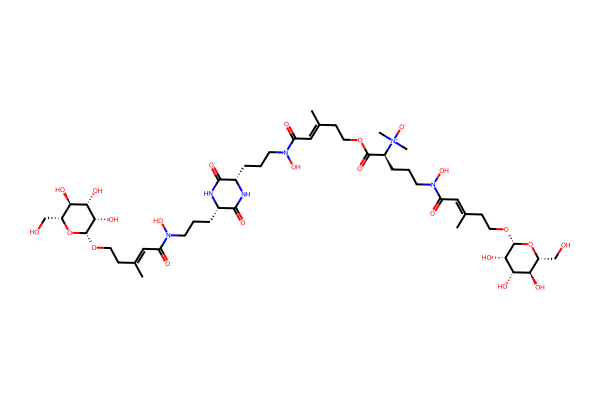

NameError: name 'Geass' is not defined

In [116]:
beau = Chem.MolFromSmiles('C/C(=C\C(=O)N(CCC[C@H]1C(=O)N[C@H](C(=O)N1)CCCN(C(=O)/C=C(\C)/CCOC(=O)[C@H](CCCN(C(=O)/C=C(\C)/CCO[C@H]2[C@H]([C@H]([C@@H]([C@H](O2)CO)O)O)O)O)[N+](C)(C)[O-])O)O)/CCO[C@H]3[C@H]([C@H]([C@@H]([C@H](O3)CO)O)O)O')
display(beau)

geass = Geass()
prods = geass.get_fragments(beau)
geass.show_connections_graph()

# Fragment C/C(=C\C(=O)O)CCO  >  LTS0069744: (2e)-5-hydroxy-3-methylpent-2-enoic acid

In [ ]:
fora = Chem.MolFromSmiles('CO[C@H]1[C@@H](OC(=O)c2ccc(C)[nH]2)[C@@H](O)[C@H](Oc2ccc3c(O)c(NC(=O)c4ccc(O)c(CC=C(C)C)c4)c(=O)oc3c2Cl)OC1(C)C')
display(fora)

geass = Geass()
prods = geass.get_fragments(fora)
geass.show_connections_graph()

In [ ]:
df1 = pd.read_csv('geass_NPA_fragments.csv', header=None, names=['raw'], sep=';')
df1[['ID', 'part2']] = df1['raw'].str.split(',', n=1, expand=True)
df1['part2'] = df1['part2'].str.split(',')
df1['compound'] = df1['part2'].apply(lambda x: x[0])
df1['n_frags'] = df1['part2'].apply(lambda x: len(x))
df1 = df1.sort_values(by='n_frags', ascending=False).head(20).reset_index(drop=True)
PandasTools.AddMoleculeColumnToFrame(df1, smilesCol='compound')

bonds = []
for row in df1.itertuples():
    geass = Geass()
    b = set(list(geass.get_bonds_to_break(row.ROMol).values()))
    bonds.append(b)

df1['bonds'] = bonds
df1

In [ ]:
import matplotlib.pyplot as plt
from pandas.plotting import table

fig, ax = plt.subplots(figsize=(8, 3))  # Adjust figure size to match table
ax.axis('off')

# Adjust colWidths to control individual column widths (values are fractions of the figure width)
tbl = table(ax, df1[['ID', 'bonds', 'n_frags']], loc='center', cellLoc='center', colWidths=[0.2, 0.5, 0.2])
tbl.auto_set_font_size(False)
tbl.set_fontsize(10)
tbl.scale(1, 1.5)

plt.show()

In [ ]:
mol = Chem.MolFromSmiles(df1.iloc[19]['compound'][0])
display(mol)

geass = Geass()
prods = geass.get_fragments(mol)
geass.show_connections_graph()

In [ ]:
display(mol)
geass.show_connections_graph()

## Visualise NP Atlas chemical space